[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_operatcalc.ipynb)


In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

# Transient processes and operational calculus

We have considered the circuits with harmonic (EM)Force. In a completely analogous analytical way, we can consider linear systems (circuits) with general dependence of (EM)force, although here the method of phase diagrams loses its simplicity and geometric vividness. Nevertheless, the transition to complex quantities still retains analytical power, since all processes obey the linear principle of superposition. For example, in presence of constant EMF, one can expect the processes of relaxation to a stationary state, which are determined only by the configuration of the circuit itself. It is essential that such processes have a switching moment (there is a key in the circuit that closes or opens). Some variants of switching the external force are shown below:

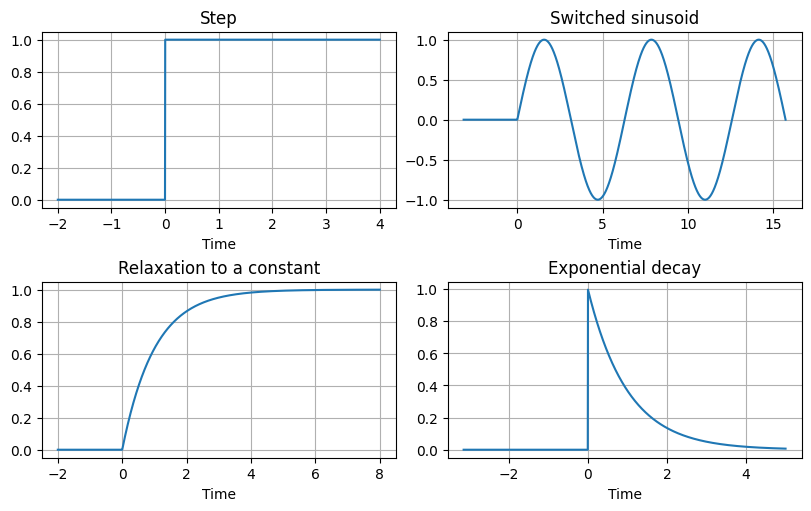

In [3]:
fig,axes=plt.subplots(2,2,figsize=(8,5),layout='constrained')
for ax,bounds,f,title in zip(axes.flat,[(-2,4),(-np.pi,5*np.pi),(-2,8),(-np.pi,5)],
    [lambda x:np.ones_like(x),np.sin,lambda x:1-np.exp(-x),lambda x:np.exp(-x)],
    ['Step','Switched sinusoid','Relaxation to a constant','Exponential decay']):
    x=np.linspace(*bounds,1500); ax.plot(x,np.heaviside(x,.5)*f(x)); ax.set(title=title,xlabel='Time'); ax.grid()
plt.show()

For transients, complex amplitudes need not have constant magnitude: both phase and amplitude can evolve. A single complex exponential combines rotation and dilation in the complex plane; a general transient is represented by a superposition of such components. Linearity allows us to describe a circuit by an impedance depending on the complex frequency variable. Initial charges and currents must also be included.

$$
\frac{d}{dt}\to \mathrm{i}\omega  \Rightarrow  \frac{d}{dt}\to p\\ \frac{{d}^{n}}{{dt}^{n}}\to {p}^{n}\tag{1}
$$

where p is a complex number representing the change of both phase and modulus. It can be interpreted as a complex ``frequency``, especially since its physical dimension is 1/s. 

Since integration is an inverse operation, then:

$$
\int f\left(t\right)dt\to  \frac{{f}_{\omega }}{\mathrm{i}\omega }\Rightarrow \int f\left(t\right)dt\to  \frac{{f}_{p}}{p}
$$

Replace the time-domain function $f\left(t\right)$ with its transform $f_p$. Heaviside used this algebraic representation of differentiation and integration extensively in electrical-circuit and transmission-line calculations.

For strictly harmonic processes, it is clear that p = i ω, as was proven earlier (Fourier transform). In case of transient processes, the real part of p is related to the characteristic relaxation time, as we will see in the example of the RC-circuit below. Impedance is a function of this variable Z(p).  But here, in contrast to the previously considered case of harmonic EMF, it is necessary to take into account the fact that before the moment of switching on, a charge  may be concentrated in some sections of the circuit (initial displacement) or current may flow (initial velocity). Since the entire subsequent evolution of the system depends only on the initial condition, all quantities in the interval t < 0 can be set equal to 0. After switching on in the EMF circuit, any physical quantity can be represented as:

$$
A\left(t\right) =A\left(0\right)+{\int }_{0}^{t}\frac{d A}{d t'}d t'\tag{2}
$$

where A(0) is the initial value. Therefore for the image

$$
{A}_{p}=A\left(0\right){\mathbb{1}}_{p} +{\left({\int }_{0}^{t}\frac{d A}{d t'}d t'\right)}_{p}=A\left(0\right){\mathbb{1}}_{p} +\frac{{\left(\frac{d A}{d t}\right)}_{p}}{p}
$$

Here $\mathbb{1}_p$ denotes the transform of the unit step:

$$
H\left(t\right) = \left\{\begin{matrix}0, t<0\\ 1, t\ge 0\end{matrix}\right.
$$

Therefore, the images of the quantity A and its derivative dA/dt are related by the relation:

$$
{\left(\frac{d A}{d t}\right)}_{p}=p \left({A}_{p}-A\left(0\right){\mathbb{1}}_{p}\right)
$$

In the following we will assume that all functions of time are proportional to the function $H\left(t\right)$, which means that switching on occurs at t=0. Then the function ${t}^{n}/n!$ corresponds to:

$$
{\left(\frac{{t}^{n}}{n!}\right)}_{p}=\frac{{\mathbb{1}}_{p}}{{p}^{n}}
$$

The derivative of the causal ramp $tH\left(t\right)$ is the Heaviside step function, so

$$
t = {\int }_{0}^{t}H\left(t'\right) dt'\Rightarrow {\mathbb{1}}_{p}=1/p\\ {\left(\frac{{t}^{n}}{n!}\right)}_{p}=\frac{1}{{p}^{n+1}}
$$

As a result, the image of the derivative  in the presence of the initial value finally has the form:

$$
{\left(\frac{d A}{d t}\right)}_{p}=p {A}_{p}-A\left(0\right)
$$

As an illustration, let us consider the simplest problem of discharging a capacitor through a resistor. The solution to this problem is known and follows directly from:

$$
q/C+\frac{d q}{d t} R=0\Rightarrow q\left(t\right)={q}_{0}{e}^{-\frac{t}{R C}}
$$

Transforming the discharge equation gives

$$
\frac{{q}_{p}}{C}+{I}_{p}R=\frac{{q}_{p}}{C}+\left(p {q}_{p}-q\left(0\right)\right)R\Rightarrow {q}_{p}=\frac{q\left(0\right)}{{p}_{0}+p}, {p}_{0}=\frac{1}{R C}
$$

i.e.

$$
{\left(exp\left(-{p}_{0}t\right)\right)}_{p}\to \frac{1}{p+{p}_{0}}
$$

and therefore

$$
{\left(exp\left({p}_{0}t\right)\right)}_{p}\to \frac{1}{p-{p}_{0}}
$$

from here we get

$$
{\left(\sinh{\left({p}_{0}t\right)}\right)}_{p}\to \frac{{p}_{0}}{{p}^{2}-{p}_{0}^{2}},{\left(\cosh{\left({p}_{0}t\right)}\right)}_{p}\to \frac{p}{{p}^{2}-{p}_{0}^{2}}\\ {\left(\sin{\left({\omega }_{0}t\right)}\right)}_{p}\to \frac{{\omega }_{0}}{{p}^{2}+{\omega }_{0}^{2}},{\left(\cos{\left({\omega }_{0}t\right)}\right)}_{p}\to \frac{p}{{p}^{2}+{\omega }_{0}^{2}}
$$

Mathematically, this is the Laplace transform, provided the integral converges:

$$
{A}_{p}={\int }_{0}^{\infty }A\left(t\right) {e}^{-p t}d t, Re p >0\\ {\left(-1\right)}^{n}{t}^{n}A\left(t\right)\to \frac{{d}^{n} {A}_{p}}{d {p}^{n}},   \frac{A\left(t\right)}{t}\to {\int }_{p}^{\infty }{A}_{p}d p, \\ {\left({\int }_{0}^{t}A\left(t'\right) d t'\right)}_{p}={\int }_{0}^{\infty }{\int }_{0}^{t}A\left(t'\right) d t' {e}^{-p t}d t={\int }_{0}^{\infty }d\left(-{\int }_{0}^{t}A\left(t'\right) d t' \frac{{e}^{-p t}}{p}\right)d t+{\int }_{0}^{\infty }A\left(t\right) \frac{ {e}^{-p t}}{p}d t=\to  \frac{{A}_{p}}{p}\tag{3}
$$

The inverse transformation is

$$
A\left(t\right)=\frac{1}{2\pi  \mathrm{i}}{\int }_{a-\mathrm{i} \infty }^{a+\mathrm{i} \infty }{A}_{p} {e}^{p t}d p, Re p =a
$$

In [4]:
t=sp.symbols('t',positive=True); p=sp.symbols('p',positive=True)
n=sp.symbols('n',integer=True,nonnegative=True); omega0=sp.symbols('omega_0',positive=True)
functions=[1,t,t**n/sp.factorial(n),sp.exp(-t),sp.sin(omega0*t),sp.cos(omega0*t),sp.sqrt(t),1/sp.sqrt(t)]
transforms=[sp.laplace_transform(f,t,p,noconds=True) for f in functions]
from IPython.display import Math
for f,F in zip(functions,transforms):
    display(Math(r'\mathcal{L}\{'+sp.latex(f)+r'\}='+sp.latex(F)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$$
{\int }_{0}^{\infty }\frac{dA\left(t\right)}{dt} {e}^{-p t}d t={\left(\frac{dA\left(t\right)}{dt}\right)}_{p}={\int }_{0}^{\infty }\left(\frac{d}{dt}\left(A\left(t\right) {e}^{-p t}\right)+p A\left(t\right){e}^{-p t}\right)d t=p {A}_{p}-A\left(0\right)
$$

which is the result we obtained above. Similarly, one can show that 

$$
{\left(\frac{{d}^{2} A}{d {t}^{2}}\right)}_{p}=p \left(p {A}_{p}-A\left(0\right)\right)-A'\left(0\right)={p }^{2}{A}_{p}-p A\left(0\right)-A'\left(0\right)\\ {\left(\frac{{d}^{n} A}{d {t}^{n}}\right)}_{p}={p}^{n}{A}_{p}-{p}^{n-1}A\left(0\right)-{p}^{n-2}A'\left(0\right)-...-{A}^{\left(n-1\right)}\left(0\right)
$$

Besides from the very definition it follows that:

$$
\lim\limits_{p\to 0}p {A}_{p}=A\left(\infty \right),  \lim\limits_{p\to \infty }p {A}_{p}=A\left(0\right)
$$

The delay relations are

$$
A \left(t\right){e}^{\lambda  t}\to {A}_{p}\left(p-\lambda \right), A\left(t-\tau \right)\to {e}^{-p \tau }{A}_{p}\tag{4}
$$

and the convolution theorem (similar to the Fourier analog):

$$
\left(A*B\right)\left(t\right)={\int }_{0}^{t}A\left(t'\right)B\left(t-t'\right)d t': {\left(A*B\right)}_{p}={A}_{p}{B}_{p}
$$

Thus, the transform of a convolution is the product of the transforms.

Let’s demonstrate this method on forced oscillation problems (assuming f(t) has Laplace transform)

$$
\frac{{d}^{2} x}{d {t}^{2}}+\gamma  \frac{d x}{d t}+{\omega }_{0}^{2}x=f\left(t\right)
$$

In terms of images (Laplace transform) we have algebraic equation:

$$
{p}^{2}{x}_{p}-p x\left(0\right)-x'\left(0\right)+{\omega }_{0}^{2}{x}_{p}+\gamma  p {x}_{p}={f}_{p}\\ {x}_{p}=\frac{{f}_{p}+p x\left(0\right)+x'\left(0\right)}{{p}^{2}+\gamma  p+{\omega }_{0}^{2}}
$$

For example, take $\Gamma=0$ and a constant applied force $f\left(t\right)=f_0$, whose transform is $f_0/p$:

$$
{x}_{p}=\frac{{f}_{0}/p+p x\left(0\right)+x'\left(0\right)}{{p}^{2}+{\omega }_{0}^{2}}
$$

The resulting undamped oscillations are

$$
{x}_{p}=\frac{{f}_{0}/p+p x\left(0\right)+x'\left(0\right)}{{p}^{2}+{\omega }_{0}^{2}}
$$

In [5]:
display(sp.laplace_transform(1,t,p,noconds=True))

1/p

In [6]:
f0,x0,x1=sp.symbols('f_0 x_0 x_1',real=True)
Xp=(f0/p+p*x0+x1)/(p*p+omega0**2)
forced_solution=sp.simplify(sp.inverse_laplace_transform(Xp,p,t))
display(sp.collect(sp.expand(forced_solution),f0))

f_0*(-cos(omega_0*t)/omega_0**2 + omega_0**(-2)) + x_0*cos(omega_0*t) + x_1*sin(omega_0*t)/omega_0

## Example

The oscillatory circuit (LC-contour) is connected to an EMF with an internal resistance of r through a switch. At the beginning, the switch is closed and the system is in a stationary state. The switch is opened. The amplitude of the voltage on the capacitor is n times greater than the EMF. The oscillation period is T. Determine the parameters of the circuit. Neglect the resistance of the coil.

### Solution

In the stationary state, the current is constant and equal to I(0)=E/r , the voltage on the capacitor ${V}_{0}=0$. After opening (t=0):

$$
L \left(p {I}_{p}-I\left(0\right)\right)+\frac{{I}_{p}}{p C}=0\Rightarrow {I}_{p}=I\left(0\right)\frac{p L C}{{p}^{2}LC+1}=I\left(0\right)\frac{p}{{p}^{2}+{\omega }_{0}^{2}}\\ {q}_{p}={I}_{p}/p
$$

## Example

At the initial moment, switch 1 is closed and, after the current through the coil ${L}_{1}$ reaches the value I(0), switch 2 is closed. Determine the steady-state currents through the coils. Neglect the resistance of the coils. The internal resistance of the source is r.


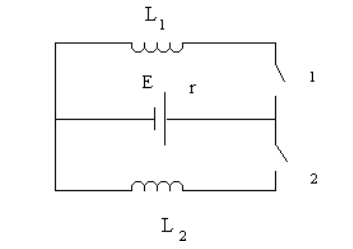



### Solution

Let’s write down straightforward relations:

$$
{L}_{1}\frac{d {I}_{1}}{dt}=E+I r={L}_{1}\frac{d {I}_{2}}{dt}, I +{I}_{1}+{I}_{2}=0, {I}_{1}\left(0\right)={I}_{01}
$$

in terms of the images

$$
{L}_{1}\left(p {I}_{1}\left(p\right)-{I}_{01}\right)={E}_{p}+I \left(p\right)r={L}_{1}p {I}_{2}\left(p\right), I\left(p\right) +{I}_{1}\left(p\right)+{I}_{2}\left(p\right)=0
$$

In [7]:
l1,l2,r=sp.symbols('L_1 L_2 R',positive=True); i01,e0=sp.symbols('I_01 E_0',real=True)
ip1,ip2,ip=sp.symbols('I_1p I_2p I_p')
ilp=sp.solve([l1*(p*ip1-i01)-e0/p-ip*r,l2*p*ip2-e0/p-ip*r,ip+ip1+ip2],(ip1,ip2,ip))
display(ilp)

{I_1p: (E_0*L_2 + I_01*L_1*L_2*p + I_01*L_1*R)/(L_1*L_2*p**2 + L_1*R*p + L_2*R*p),
 I_2p: (E_0*L_1 - I_01*L_1*R)/(L_1*L_2*p**2 + L_1*R*p + L_2*R*p),
 I_p: (-E_0*L_1 - E_0*L_2 - I_01*L_1*L_2*p)/(L_1*L_2*p**2 + L_1*R*p + L_2*R*p)}

In [8]:
final_currents=[sp.simplify(sp.limit(p*ilp[q],p,0,dir='+')) for q in (ip1,ip2,ip)]
display(*final_currents,sp.simplify(sum(final_currents))==0)

(E_0*L_2 + I_01*L_1*R)/(R*(L_1 + L_2))

L_1*(E_0 - I_01*R)/(R*(L_1 + L_2))

-E_0/R

True

## Example

A rectilinear conductive rod of length h and mass m is suspended on springs of stiffness k in a uniform field B. In the initial state, the capacitor of capacitance C is charged to voltage U. Describe the process of movement of the rod after the switch is closed.


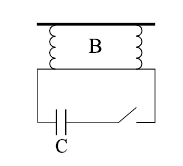



### Solution

Let us write the equations of motion of the rod taking into account the Ampere force and the current taking into account the induction EMF:

$$
\frac{{d}^{2} x}{d {t}^{2}}=-{\omega }_{0}^{2}x+\frac{d q}{d t}\frac{B h}{m}, {\omega }_{0}=\sqrt{k/m}\\  \frac{q}{C}=E=-\frac{d\Phi }{d t}=-B h\frac{d x}{d t}\Rightarrow \frac{d q}{d t}=-C B h \frac{{d}^{2}x}{d {t}^{2}}\\ \frac{{d}^{2} x}{d {t}^{2}}\left(1+\frac{C {B}^{2} {h}^{2}}{m} \right)=-{\omega }_{0}^{2}x \Rightarrow  \omega  = \frac{{\omega }_{0}}{\sqrt{1+\frac{C {B}^{2} {h}^{2}}{m}}}
$$

The answer is clear. Let’s write down the equations for images

$$
{p}^{2}{x}_{p}+{\omega }_{0}^{2}{x}_{p}-\left(p {q}_{p}-q\left(0\right)\right)\frac{B h}{m} \\ p {q}_{p}-q\left(0\right)=-C B h {p}^{2} {x}_{p}\\ q\left(0\right)=C U
$$

It is easy to solve the system wrt ${x}_{p}$, ${q}_{p}$.

$$
{x}_{p}=-q\left(0\right)\frac{B h}{m+{\left(B h\right)}^{2}C}\frac{ 1}{{p}^{2}\left(1+\frac{{\left(B h\right)}^{2}C}{m}\right)+{\omega }_{0}^{2}},\Rightarrow {\omega }^{2}=\frac{{\omega }_{0}^{2}}{1+\frac{{\left(B h\right)}^{2}C}{m}}
$$

## Example

In the circuit shown


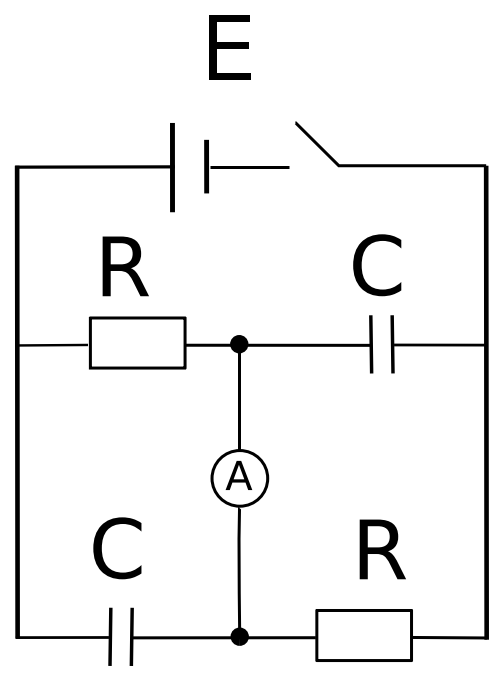


the switch is periodically shuts and opens for periods ${\tau }_{1}$ and ${\tau }_{2}$ respectively. The internal resistances of the ammeter and the source are small. What current does the ammeter show between the points?

### Solution

The solution of this problem goes like this. If the switch is shut the current is 

$$
{I}_{{\tau }_{1}}=\frac{{E}_{0}}{2R}
$$

and the capacitors become charged

$$
{U}_{C}=\frac{{E}_{0}}{2}\Rightarrow q = C\frac{{E}_{0}}{2}
$$

when it opens the current is 

$$
{I}_{{\tau }_{2}}=\frac{q}{\tau }
$$

Periodically closing and opening the switch is equivalent to a periodic applied EMF, with the transform below. Derive it using the delay relation:

$$
{E}_{p}=\frac{{E}_{0}}{p}\frac{1-{e}^{-{\tau }_{1} p }}{1-{e}^{-\left({\tau }_{1}+{\tau }_{2}\right)p }}
$$

Hint: use (4) and periodicity

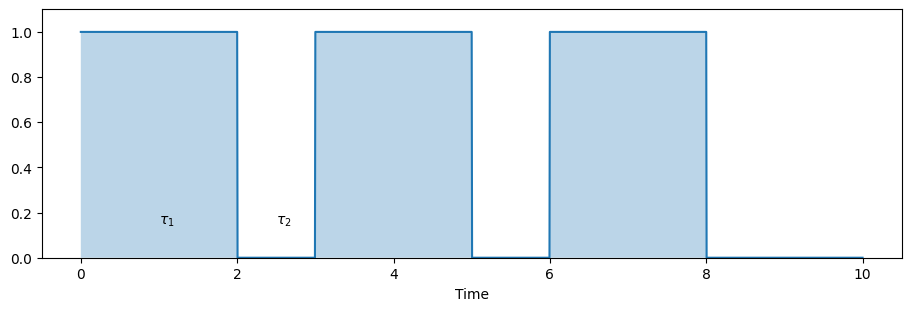

In [9]:
time=np.linspace(0,10,2001)
pulse=(time<=2).astype(float)+((time>=3)&(time<=5)).astype(float)+((time>=6)&(time<=8)).astype(float)
fig,ax=plt.subplots(figsize=(9,3),layout='constrained'); ax.fill_between(time,0,pulse,step='mid',alpha=.3); ax.plot(time,pulse)
ax.text(1,.15,r'$\tau_1$'); ax.text(2.5,.15,r'$\tau_2$'); ax.set(xlabel='Time',ylim=(0,1.1)); plt.show()

In [10]:
t1,t2=sp.symbols('tau_1 tau_2',positive=True)
# Integrate the three nonzero intervals; this avoids ambiguous step-function assumptions.
single=(1-sp.exp(-p*t1))/p
three_pulses=sp.expand(sum(sp.exp(-j*p*(t1+t2))*single for j in range(3)))
display(three_pulses,sp.simplify(three_pulses/single))

1/p - exp(-p*tau_1)/p + exp(-p*tau_1)*exp(-p*tau_2)/p - exp(-2*p*tau_1)*exp(-p*tau_2)/p + exp(-2*p*tau_1)*exp(-2*p*tau_2)/p - exp(-3*p*tau_1)*exp(-2*p*tau_2)/p

(exp(2*p*(tau_1 + tau_2)) + exp(p*(tau_1 + tau_2)) + 1)*exp(-2*p*(tau_1 + tau_2))

An ammeter with low resistance serves as a jumper through which a certain charge flows. The value of this charge per a unit of time is the required current. Actually, this is all that is needed to solve the problem. However, using the impedance method allows us to consider this circuit completely. Calculating a circuit using (complex) representing quantities is no different from an AC circuit, even taking into account the finite resistance of the ammeter. By choosing the direction of the currents and independent cycles, we write a system of equations for images:

$$
{I}_{1}R+\frac{{I}_{2}}{p C}={E}_{p},  {I}_{4}R+\frac{{I}_{3}}{p C}={E}_{p},\\ {I}_{1}R-{I}_{a}r+{I}_{4}R = {E}_{p}, {I}_{1}+{I}_{a}={I}_{2},  {I}_{4}+{I}_{a}={I}_{3}, I={I}_{1}+{I}_{3}
$$

Solution of this system:

In [11]:
c,r0=sp.symbols('C R_0',positive=True); ep=sp.symbols('E_p')
ip1,ip2,ip3,ip4,ipa,ip=sp.symbols('I_1p I_2p I_3p I_4p I_Ap I_p')
circuit_eqs=[ip1*r+ip2/(p*c)-ep,ip4*r+ip3/(p*c)-ep,ip1*r+ipa*r0+ip4*r-ep,ip1-ipa-ip2,ip3+ipa-ip4,ip-ip1-ip3]
circuit_solution={q:sp.factor(value) for q,value in sp.solve(circuit_eqs,(ip1,ip2,ip3,ip4,ipa,ip)).items()}
display(circuit_solution)
assert all(sp.simplify(eq.subs(circuit_solution))==0 for eq in circuit_eqs)

{I_1p: E_p*(C*R_0*p + 1)/(C*R*R_0*p + 2*R + R_0),
 I_2p: C*E_p*p*(R + R_0)/(C*R*R_0*p + 2*R + R_0),
 I_3p: C*E_p*p*(R + R_0)/(C*R*R_0*p + 2*R + R_0),
 I_4p: E_p*(C*R_0*p + 1)/(C*R*R_0*p + 2*R + R_0),
 I_Ap: -E_p*(C*R*p - 1)/(C*R*R_0*p + 2*R + R_0),
 I_p: E_p*(C*R*p + 2*C*R_0*p + 1)/(C*R*R_0*p + 2*R + R_0)}

brings the ammeter current:

In [12]:
display(circuit_solution[ipa])

-E_p*(C*R*p - 1)/(C*R*R_0*p + 2*R + R_0)

$$
{I}_{a}= {E}_{p}\frac{ 1-R C p}{r+R \left(2+C p r\right)} \Rightarrow  r\to 0 ,   {I}_{a}=\frac{{E}_{p}}{2R} \left(1-R C p\right)
$$

The current averaged over one period is

In [13]:
periodic_emf=e0/p*(1-sp.exp(-t1*p))/(1-sp.exp(-(t1+t2)*p))
# The p->0 limit gives the mean of this periodic steady response, not a pointwise final value.
mean_current=sp.simplify(sp.limit((p*circuit_solution[ipa]).subs({r0:0,ep:periodic_emf}),p,0,dir='+'))
display(mean_current)

E_0*tau_1/(2*R*(tau_1 + tau_2))

The negative sign indicates a current opposite to the chosen reference direction. Full time-dependent response, including its alternating part, has the following transform:

In [14]:
display(sp.factor(circuit_solution[ipa].subs(ep,periodic_emf)))

E_0*(C*R*p - 1)*(exp(p*tau_1) - 1)*exp(-p*tau_1)/(p*(-1 + exp(-p*tau_1)*exp(-p*tau_2))*(C*R*R_0*p + 2*R + R_0))

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)